# Project 1 – Pass-07


## Problem Definition



Business problem: Predict whether a customer will make a successfull transaction,

Data Science problem: This is a supervised learning and classification problem. I will use the Gaussian Naive Bayes model





## Data Collection

### Imports

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn import datasets, metrics, model_selection

### File Paths

In [ ]:
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.1-Transactions/Data/Transaction.train.big.csv'

### Load data

In [ ]:
#load data
transaction_df= pd.read_csv(
    url,
    usecols=range(15),
    nrows=10_000,
)

### Head

In [ ]:
# first few rows
transaction_df.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.476,NaN,NaN,NaN
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Tail

In [ ]:
# last few rows
transaction_df.tail()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
9995,9995,train_9995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,9996,train_9996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,9997,train_9997,0.0,4.1463,20.3755,14.8105,NaN,6.0432,NaN,NaN,1.2462,6.5467,NaN,NaN,NaN
9998,9998,train_9998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9999,9999,train_9999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Shape

In [ ]:
# shape of data frame
transaction_df.shape

#output (# of rows, # of columns)

(10000, 15)

### Size

In [ ]:
# size of data frame
transaction_df.size

150000

### Info

In [ ]:
# display meta-data
transaction_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  10000 non-null  int64  
 1   ID_code     10000 non-null  object 
 2   target      1686 non-null   float64
 3   var_0       1686 non-null   float64
 4   var_1       1686 non-null   float64
 5   var_2       1686 non-null   float64
 6   var_3       0 non-null      float64
 7   var_4       1686 non-null   float64
 8   var_5       0 non-null      float64
 9   var_6       0 non-null      float64
 10  var_7       1686 non-null   float64
 11  var_8       1686 non-null   float64
 12  var_9       0 non-null      float64
 13  var_10      0 non-null      float64
 14  var_11      0 non-null      float64
dtypes: float64(13), int64(1), object(1)
memory usage: 1.1+ MB


## Summary statistics

### Describe

In [ ]:
# display summary statistics
transaction_df.describe()


,Unnamed: 0,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
count,10000.00000,1686.000000,1686.000000,1686.000000,1686.000000,0.0,1686.000000,0.0,0.0,1686.000000,1686.000000,0.0,0.0,0.0
mean,4999.50000,0.098458,7.493109,15.840630,12.667966,NaN,-0.461214,NaN,NaN,1.276329,6.812313,NaN,NaN,NaN
std,2886.89568,0.298021,3.090435,3.086651,4.187706,NaN,6.014515,NaN,NaN,5.103567,0.374905,NaN,NaN,NaN
min,0.00000,0.000000,-0.101600,7.700200,3.218700,NaN,-16.855000,NaN,NaN,-11.731000,5.688300,NaN,NaN,NaN
25%,2499.75000,0.000000,5.174825,13.739200,9.601600,NaN,-4.893675,NaN,NaN,-2.458950,6.559500,NaN,NaN,NaN
50%,4999.50000,0.000000,7.379350,15.992700,12.478250,NaN,-0.190200,NaN,NaN,1.080350,6.795350,NaN,NaN,NaN
75%,7499.25000,0.000000,9.708875,18.155675,15.725050,NaN,3.730575,NaN,NaN,5.107175,7.071325,NaN,NaN,NaN
max,9999.00000,1.000000,16.716500,23.971700,24.828500,NaN,15.973100,NaN,NaN,17.441800,7.877900,NaN,NaN,NaN


### Target value counts

NOTE: the ‘target’ column indicates a successful transaction (‘1’) or a no-transaction (‘0’). Verify these are the only values in that column, and that there are no nulls.

In [ ]:
# value_counts on target ; include nulls
transaction_df['target'].value_counts(dropna=False)

,count
target,
NaN,8314
0.0,1520
1.0,166


In [ ]:
#normalize value counts on target ; include nulls
transaction_df['target'].value_counts(normalize=True, dropna=False)

,proportion
target,
NaN,0.8314
0.0,0.1520
1.0,0.0166


### Nulls

In [ ]:
# look for nulls
transaction_df.isnull().sum().sort_values(ascending=False)



,0
var_3,10000
var_6,10000
var_11,10000
var_9,10000
var_10,10000
var_5,10000
var_0,8314
target,8314
var_4,8314
var_2,8314


In [ ]:
# look for nulls, display relative frequency
null_sum = transaction_df.isnull().sum()
null_freq = null_sum / transaction_df.shape[0] * 100
null_freq.sort_values()

#Output- target has 82% percent null values

,0
Unnamed: 0,0.00
ID_code,0.00
target,83.14
var_0,83.14
var_1,83.14
var_2,83.14
var_4,83.14
var_8,83.14
var_7,83.14
var_3,100.00


### Column data types

In [ ]:
# display data types
transaction_df.dtypes.sort_values()

,0
Unnamed: 0,int64
target,float64
var_0,float64
var_1,float64
var_2,float64
var_3,float64
var_4,float64
var_5,float64
var_6,float64
var_7,float64


### Unique elements

In [ ]:
# number of unique elements in every column (works on the whole dataframe)
transaction_df.nunique().sort_values(ascending=False)

,0
Unnamed: 0,10000
ID_code,10000
var_4,1678
var_7,1677
var_0,1677
var_2,1672
var_1,1663
var_8,1596
target,2
var_3,0


In [ ]:
# actual unique values in one column
transaction_df['target'].unique()

array([nan,  0.,  1.])

## Data Cleaning



Backup #1

In [ ]:
# backup copy of the original data
transaction_df_backup= transaction_df.copy()


In [ ]:
# restore from backup
transaction_df=transaction_df_backup.copy()

### Drop rows with no target
  - The target has 83% nulls. Model cant learn from rows with no answer, remove them first

Selected `target` for the target and drop the rows with null values

In [ ]:
#transaction_df.iloc[:5].dropna(subset=['target'])

In [ ]:
# Keep only the rows where target is not missing
transaction_df_target=transaction_df.dropna(subset=['target']).copy()
transaction_df_target.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,NaN,NaN,NaN
5,5,train_5,0.0,14.6962,18.3383,17.4788,NaN,-9.1355,NaN,NaN,-6.4882,6.0821,NaN,NaN,NaN
11,11,train_11,0.0,4.4949,14.4142,13.2219,NaN,4.9140,NaN,NaN,4.0501,5.8144,NaN,NaN,NaN
15,15,train_15,0.0,4.9657,16.2867,17.9579,NaN,0.6017,NaN,NaN,-5.4904,6.6670,NaN,NaN,NaN
19,19,train_19,0.0,9.4287,18.7822,10.7630,NaN,-0.7532,NaN,NaN,8.8477,6.8045,NaN,NaN,NaN


In [ ]:
transaction_df_target.head(10) # this is to check

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,NaN,NaN,NaN
5,5,train_5,0.0,14.6962,18.3383,17.4788,NaN,-9.1355,NaN,NaN,-6.4882,6.0821,NaN,NaN,NaN
11,11,train_11,0.0,4.4949,14.4142,13.2219,NaN,4.9140,NaN,NaN,4.0501,5.8144,NaN,NaN,NaN
15,15,train_15,0.0,4.9657,16.2867,17.9579,NaN,0.6017,NaN,NaN,-5.4904,6.6670,NaN,NaN,NaN
19,19,train_19,0.0,9.4287,18.7822,10.7630,NaN,-0.7532,NaN,NaN,8.8477,6.8045,NaN,NaN,NaN
22,22,train_22,0.0,6.7023,18.0127,18.4424,NaN,-5.1010,NaN,NaN,-6.2877,6.9091,NaN,NaN,NaN
29,29,train_29,0.0,11.2902,7.7553,6.6189,NaN,-7.0587,NaN,NaN,-2.8962,7.1432,NaN,NaN,NaN
33,33,train_33,0.0,4.6761,14.6116,12.4063,NaN,-9.6457,NaN,NaN,-3.5926,6.1751,NaN,NaN,NaN
35,35,train_35,0.0,10.5404,10.9793,11.0240,NaN,2.2579,NaN,NaN,8.7554,7.2437,NaN,NaN,NaN
46,46,train_46,0.0,5.6315,13.2825,20.9955,NaN,3.1402,NaN,NaN,-0.9188,6.6585,NaN,NaN,NaN


### Backup #2

In [ ]:
# make backup
transaction_df_target_backup = transaction_df_target.copy()

In [ ]:
# restore from back up
transaction_df_target = transaction_df_target_backup.copy()

### Address any rows with nulls

- If the number of nulls in a column is low, it would be easiest to drop the row.
- If the number of nulls in a column is high, it would be easiest to drop the column.
- If the number of nulls in a column is between the low and high, one should impute values for the nulls.

In [ ]:
transaction_df_target.isnull().sum().sort_values (ascending=False) # show me where the null value are

,0
var_3,1686
var_6,1686
var_11,1686
var_9,1686
var_10,1686
var_5,1686
ID_code,0
var_2,0
var_1,0
var_0,0


In [ ]:
# Remove all the null row under target
transaction_df_target_clean =transaction_df_target.dropna(axis ='columns')
transaction_df_target_clean.isnull().sum().sort_values(ascending=False)

transaction_df_target_clean.head()



,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_4,var_7,var_8
3,3,train_3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760
5,5,train_5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821
11,11,train_11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144
15,15,train_15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670
19,19,train_19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045


In [ ]:
#DROP THE 'UNMAMED:0 and id_code, colums)
transaction_df_target_clean = transaction_df_target_clean.drop (columns=['Unnamed: 0','ID_code'])
transaction_df_target_clean

,target,var_0,var_1,var_2,var_4,var_7,var_8
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045
...,...,...,...,...,...,...,...
9978,0.0,3.7065,12.2215,12.0781,-4.5570,-2.0199,6.4613
9982,0.0,7.4992,12.3931,15.6143,3.9159,-6.4257,6.4960
9983,0.0,3.6195,11.1681,6.0020,2.7570,-1.3041,7.3073
9993,0.0,6.6722,17.1154,9.2696,8.2625,4.0066,6.6464


## Recommendations for Data Cleaning

**1. Identifier Columns**
- **Two columns:** `Unnamed: 0` is row numbers and `ID_code` is customer ID. cannot help predict anything
- **Recommendation:** Drop both columns. (I kept only `target` and `var_0` to `var_4`.)

**2. Null values:** No feature column have nulls. no action needed

**3. Target nulls:** 82% null values, rows with nulls are dropped

**4. Feature columns with high null counts:** None

**5. Medium null counts:** none

**6. Low null counts:** none

**7. Null rows:** none


## Exploratory Data Analysis ##

### Normal distribution of features:histogram

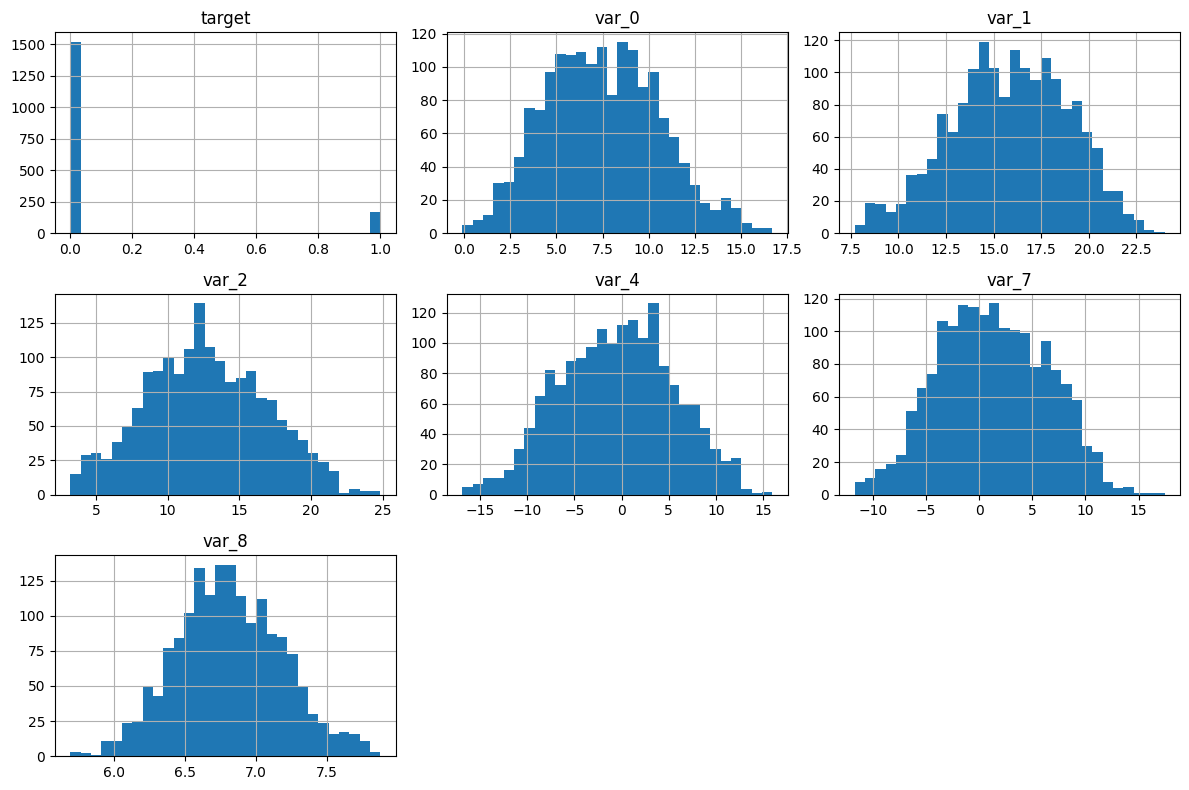

In [ ]:
# Display a histogram - overview of target and the 5 features

transaction_df_target_clean.hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()


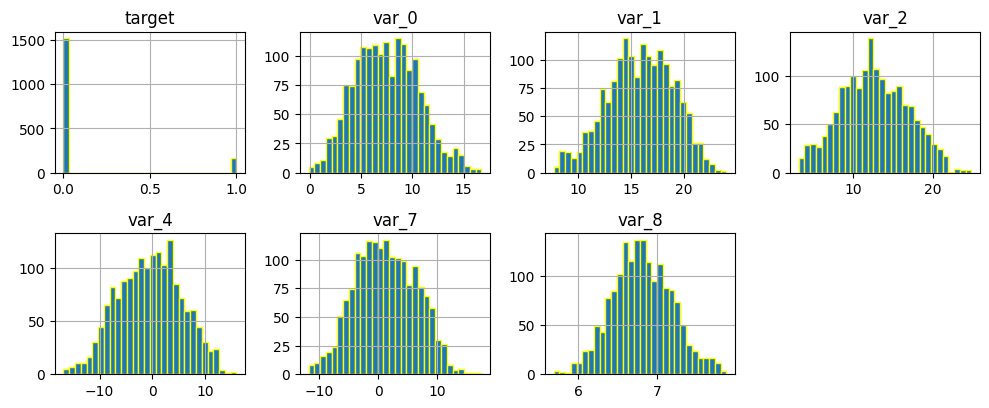

In [ ]:
# Check the distributions of the 20 features (var_0 to var_19)

transaction_df_target_clean.hist(
  figsize=(10,10), # size of the whole picture in inches(width,height)
  layout=(5,4),    # 5 rows, 4 column= 20 boxes
  bins=30,         # more bars, so the shape is clear
  edgecolor= "yellow"
)
plt.tight_layout()
plt.show()
#output- each graph look like a bell-shaped (first GNB assumption)

### Independence of features: Correlation matrix

In [ ]:
# Calculate a correlation matrix (target & features)
transaction_df_target_clean.corr()

,target,var_0,var_1,var_2,var_4,var_7,var_8
target,1.000000,0.037293,-0.026791,-0.041715,-0.038164,0.003941,0.021176
var_0,0.037293,1.000000,0.005254,-0.008940,-0.032564,0.019145,-0.004555
var_1,-0.026791,0.005254,1.000000,-0.006304,0.027493,0.033324,0.005790
var_2,-0.041715,-0.008940,-0.006304,1.000000,0.032350,0.015287,-0.007869
var_4,-0.038164,-0.032564,0.027493,0.032350,1.000000,0.016244,-0.016298
var_7,0.003941,0.019145,0.033324,0.015287,0.016244,1.000000,-0.031002
var_8,0.021176,-0.004555,0.005790,-0.007869,-0.016298,-0.031002,1.000000


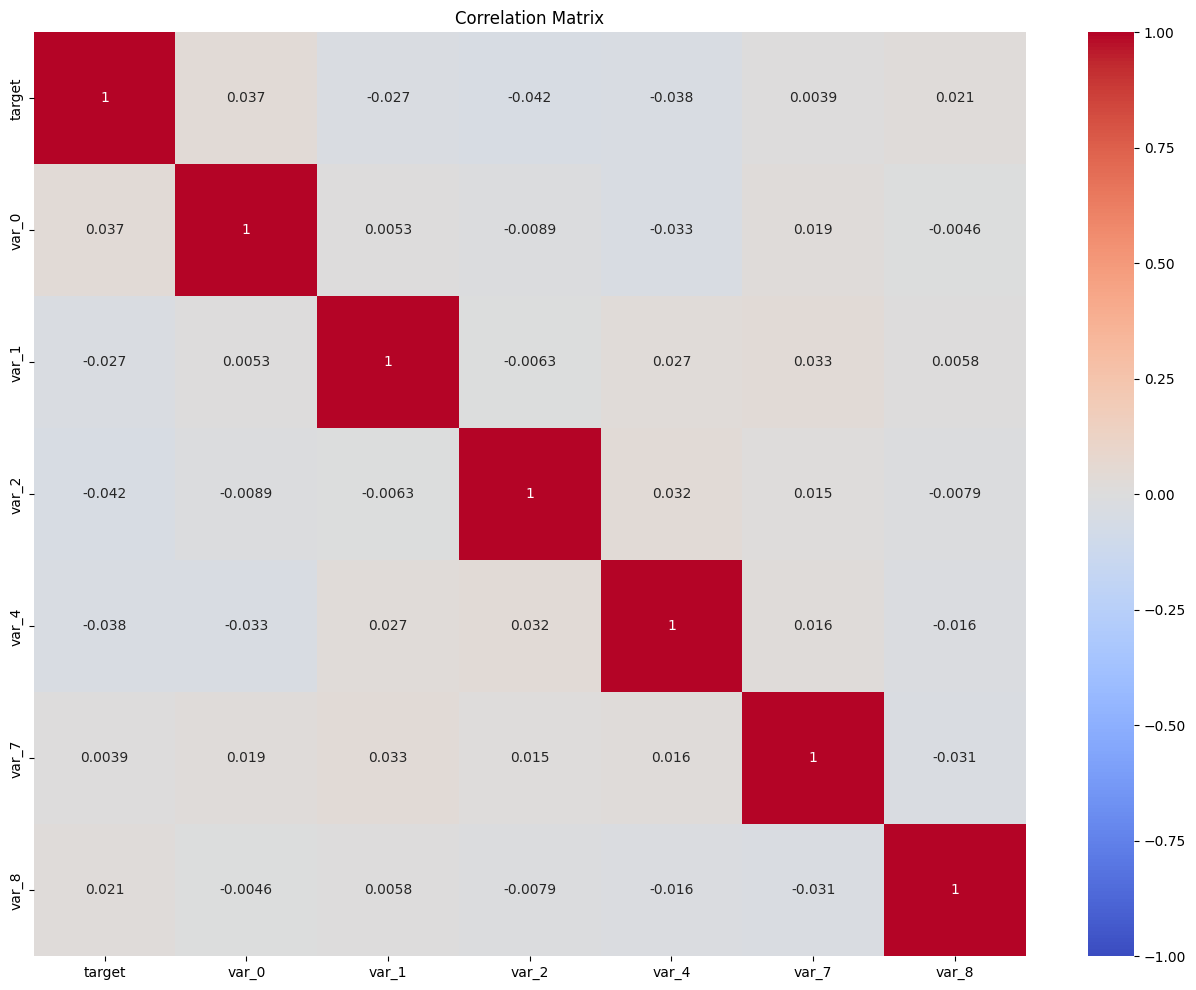

In [ ]:
# Display the correlation matrix

plt.figure(figsize=(16, 12))
sns.heatmap(transaction_df_target_clean.corr(),
            annot=True,
            cmap='coolwarm',  # blue = negative, red = positive
            center=0,         # white = no correlation
            vmin=-1, vmax=1)  # full correlation range
plt.title('Correlation Matrix')
plt.show()


In [ ]:
# select the features
feature_cols =[] #start with an empty list to hold the features
for col in transaction_df_target_clean.columns: #look at each column name
  if col.startswith ('var_'): #if the name start with 'var_, it's a feature
    feature_cols.append(col)
# check the list (show 50 names)
print(feature_cols)
print(len(feature_cols))

['var_0', 'var_1', 'var_2', 'var_4', 'var_7', 'var_8']
6


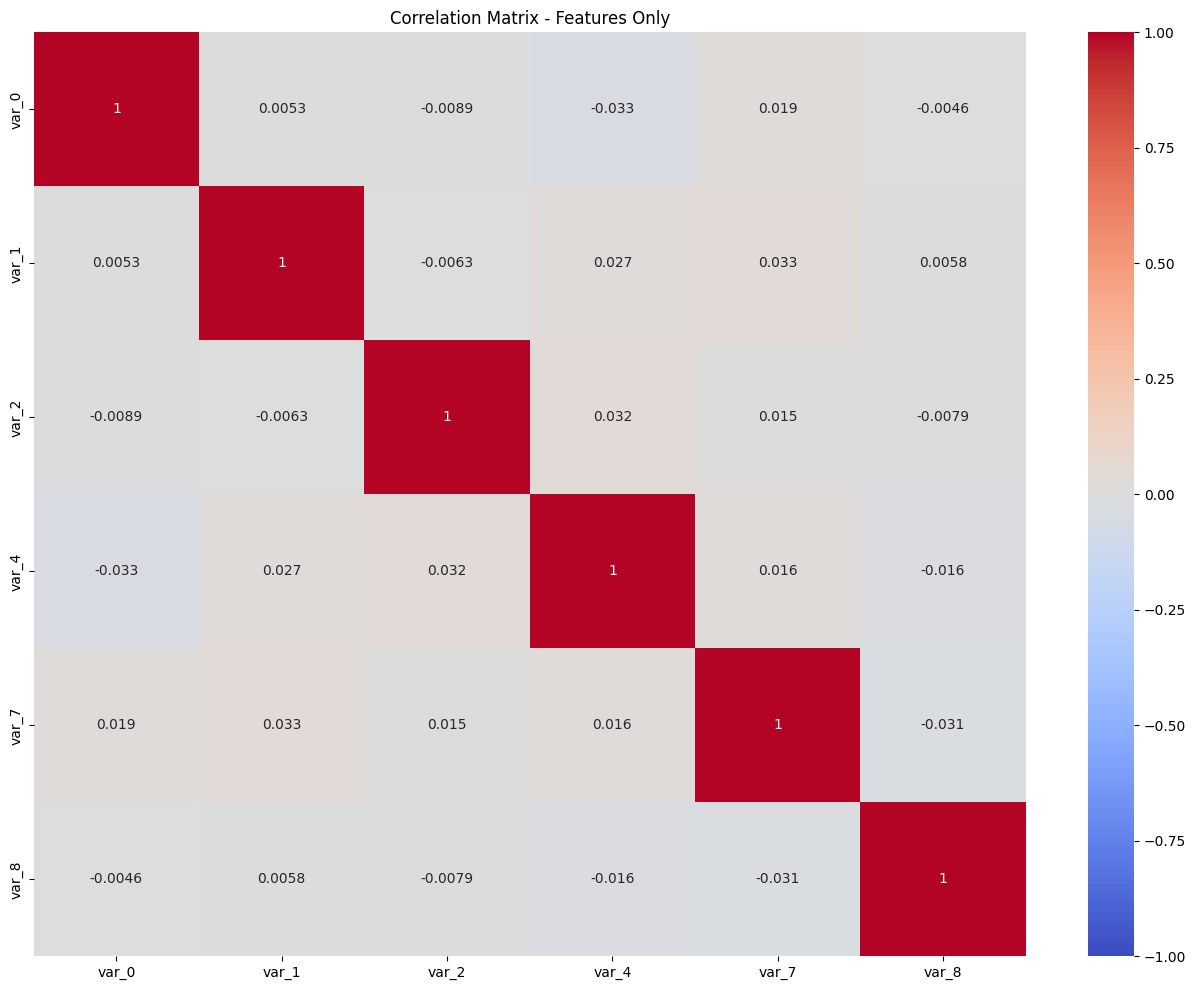

In [ ]:
# Calculate a correlation matrix (features only)
transaction_df_features_only = transaction_df_target_clean[feature_cols]
feature_corr = transaction_df_features_only.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(feature_corr,
            annot=True,
            cmap='coolwarm',  # blue = negative, red = positive
            center=0,         # white/gray = no correlation
            vmin=-1, vmax=1)  # full correlation range
plt.title('Correlation Matrix - Features Only')
plt.show()

#output- correlation between features are near 0
#look independent, 2nd GNB assumption


In [ ]:
# Create two data frames

# no transaction (target= 0)
transaction_df_no_success= transaction_df_target_clean[transaction_df_target_clean['target'] == 0].copy()

# successful transaction (target= 1)
transaction_df_successful= transaction_df_target_clean[transaction_df_target_clean['target'] == 1].copy()


print(type(transaction_df_successful))
print(type(transaction_df_no_success))

print(transaction_df_successful.shape)
print(transaction_df_no_success.shape)


<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.frame.DataFrame'>
(166, 7)
(1520, 7)


## Data Processing

### Single Cross-validation

In [ ]:
# Split data from into target and features
target =transaction_df_target_clean['target'].copy()
features= transaction_df_target_clean [feature_cols].copy()



In [ ]:
# Train test split
x_train, x_test, y_train, y_test = train_test_split( features, target, test_size=0.25, random_state=42)

In [ ]:
# verify shape of each data set from Train test split
for i in (x_train, x_test,y_train,y_test):
  print(i.shape)
  print(type(i))

(1264, 6)
<class 'pandas.core.frame.DataFrame'>
(422, 6)
<class 'pandas.core.frame.DataFrame'>
(1264,)
<class 'pandas.core.series.Series'>
(422,)
<class 'pandas.core.series.Series'>


### Model

In [ ]:
# Create an empty GNB model
modelGNB= GaussianNB()

### Fit

In [ ]:
# Train ( fit ) the model
modelGNB.fit(x_train,y_train)

GaussianNB()

### Prediction

In [ ]:
# Make prediction using the model
pred_result= modelGNB.predict(x_test)

### Performance

In [ ]:
# Calculate the accuracy
accuracy=metrics.accuracy_score(y_test,pred_result)
accuracy*100

89.57345971563981

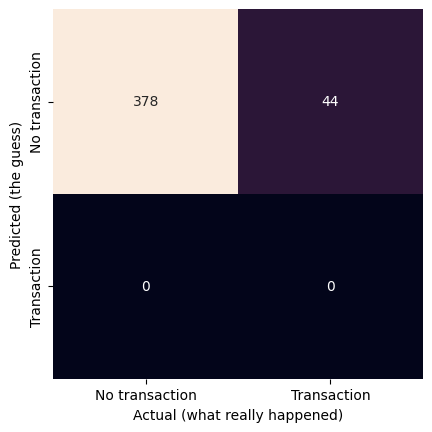

In [ ]:
# Display a confusion matrix
mat = metrics.confusion_matrix(y_test,pred_result)
names = ['No transaction', 'Transaction']
sns.heatmap(mat.T,
    square=True,
    annot=True,
    fmt='d',
    cbar=False,
    xticklabels=names,  #names start left to right
    yticklabels=names,  #names start from top to bottom
)

plt.xlabel('Actual (what really happened)')
plt.ylabel('Predicted (the guess)') ;

In [ ]:
#Classification report
print(metrics.classification_report(y_test, pred_result,zero_division=0 ))

#output show a warning message because model did not guess successful transactio
# zero_division=0 to remove the warning message


              precision    recall  f1-score   support

         0.0       0.90      1.00      0.94       378
         1.0       0.00      0.00      0.00        44

    accuracy                           0.90       422
   macro avg       0.45      0.50      0.47       422
weighted avg       0.80      0.90      0.85       422



### Communication of Results

The target show no transaction (‘0’) or  successful transaction (‘1’).

**Accuracy:** 90%


**Confusion matrix:**

 - 224: guessed no transaction, actually no transaction → right
  
 - 23: guessed no transaction, actually successfull transaction → wrong

 - 2: guessed sucessful transaction, actually no transaction -> wrong

 - 1: guess sucessful transaction, actually transaction ->right
  
**Classification report:**
  
  - Recall for successfull transaction: 0.04
    - The model found 1 out 24 successfull transaction.

  - Precision for successfull transaction: 0.33
    - The model said successfull transaction 3 times, right once  

  - 90% is just for the no transaction customer.

**Takeaway:** The model guessed "no transaction" for most customer transaction.

